## 1. Environment Setup & Data Loading
* **Objective**: Import required machine learning libraries and dynamically locate dataset files across different Kaggle working directory structures[cite: 1].
* **Reproducibility**: Fixes the random seed (`SEED = 42`) to ensure consistent model training results across folds.

In [1]:
import os
import pandas as pd
import numpy as np
import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# Fix random seed for reproducibility
SEED = 42

# Dynamically locate train, test, and sample submission paths
train_path, test_path, sample_sub_path = None, None, None
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename == 'train.csv' and not train_path:
            train_path = os.path.join(dirname, filename)
        elif filename == 'test.csv' and not test_path:
            test_path = os.path.join(dirname, filename)
        elif filename == 'sample_submission.csv' and not sample_sub_path:
            sample_sub_path = os.path.join(dirname, filename)

train_path = train_path or '/kaggle/input/train.csv'
test_path = test_path or '/kaggle/input/test.csv'

# Load datasets
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
sample_sub = pd.read_csv(sample_sub_path) if sample_sub_path and os.path.exists(sample_sub_path) else None

print(f"Train Shape: {train_df.shape}")
print(f"Test Shape: {test_df.shape}")

Train Shape: (8000, 17)
Test Shape: (2000, 17)


## 2. Advanced Feature Engineering Pipeline (With Weekend Rush & Spatial Interaction)
* **Data Hygiene**: Cleans negative fares and upper-quantile outliers strictly from the training set *without dropping test rows*, ensuring the test set shape remains fully intact.
* **Temporal Patterns**: Separates corporate weekday rush hours (8-10 AM, 5-8 PM) from leisure-driven weekend evening rush hours (5 PM to 10 PM).
* **Spatial & Distance Pricing**: Calculates weekend-specific destination popularity and multiplies it by trip distance (`weekend_far_popular_zone`) to model higher commuter prices for far-away leisure hotspots.

In [2]:
def advanced_weekend_feature_engineering(train_df, test_df):
    train_df = train_df.copy()
    test_df = test_df.copy()
    
    # Train-only data hygiene (Never drop rows from test set!)
    if 'total_amount' in train_df.columns:
        train_df = train_df[train_df['total_amount'] > 0].reset_index(drop=True)
        fare_cap = train_df['total_amount'].quantile(0.999)
        train_df = train_df[train_df['total_amount'] <= fare_cap].reset_index(drop=True)
    if 'trip_distance' in train_df.columns:
        train_df = train_df[train_df['trip_distance'] > 0].reset_index(drop=True)

    global_mean_fare = train_df['total_amount'].mean() if 'total_amount' in train_df.columns else 15.0

    # Extract weekend subsets safely from train for spatial maps
    pickup_col_tr = next((col for col in ['pickup_datetime', 'tpep_pickup_datetime'] if col in train_df.columns), None)
    if pickup_col_tr:
        train_df[pickup_col_tr] = pd.to_datetime(train_df[pickup_col_tr])
        train_df['temp_dayofweek'] = train_df[pickup_col_tr].dt.dayofweek
        train_df['temp_is_weekend'] = train_df['temp_dayofweek'].isin([5, 6])
        train_weekend = train_df[train_df['temp_is_weekend']]
    else:
        train_weekend = pd.DataFrame()

    # Weekend & Standard Spatial Mapping dictionaries
    weekend_do_fare_map = train_weekend.groupby('DOLocationID')['total_amount'].mean().to_dict() if 'DOLocationID' in train_weekend.columns and 'total_amount' in train_weekend.columns else {}
    weekend_do_count_map = train_weekend.groupby('DOLocationID').size().to_dict() if 'DOLocationID' in train_weekend.columns else {}
    
    pu_fare_map = train_df.groupby('PULocationID')['total_amount'].mean().to_dict() if 'PULocationID' in train_df.columns and 'total_amount' in train_df.columns else {}
    do_fare_map = train_df.groupby('DOLocationID')['total_amount'].mean().to_dict() if 'DOLocationID' in train_df.columns and 'total_amount' in train_df.columns else {}
    
    route_freq = {}
    if 'PULocationID' in train_df.columns and 'DOLocationID' in train_df.columns:
        train_df['route_pair'] = train_df['PULocationID'].astype(str) + "_" + train_df['DOLocationID'].astype(str)
        test_df['route_pair'] = test_df['PULocationID'].astype(str) + "_" + test_df['DOLocationID'].astype(str)
        route_freq = train_df['route_pair'].value_counts().to_dict()

    train_df = train_df.drop(columns=['temp_dayofweek', 'temp_is_weekend'], errors='ignore')

    def process_df(df):
        df = df.copy()
        
        pickup_col = next((col for col in ['pickup_datetime', 'tpep_pickup_datetime'] if col in df.columns), None)
        dropoff_col = next((col for col in ['dropoff_datetime', 'tpep_dropoff_datetime'] if col in df.columns), None)
        
        if pickup_col:
            df[pickup_col] = pd.to_datetime(df[pickup_col])
            df['hour'] = df[pickup_col].dt.hour
            df['dayofweek'] = df[pickup_col].dt.dayofweek
            df['month'] = df[pickup_col].dt.month
            df['is_weekend'] = df['dayofweek'].isin([5, 6]).astype(int)
            
            # Weekday Rush Hours (8-10 AM, 5-8 PM)
            df['is_rush_hour'] = ((~df['is_weekend'].astype(bool)) & ((df['hour'].between(8, 10)) | (df['hour'].between(17, 20)))).astype(int)
            
            # Weekend Evening Rush Hours (5 PM to 10 PM on Sat/Sun)
            df['is_weekend_rush_hour'] = (df['is_weekend'].astype(bool) & df['hour'].between(17, 22)).astype(int)

        if pickup_col and dropoff_col:
            df[dropoff_col] = pd.to_datetime(df[dropoff_col])
            df['trip_duration_min'] = (df[dropoff_col] - df[pickup_col]).dt.total_seconds() / 60.0
            df['speed_mph'] = df['trip_distance'] / ((df['trip_duration_min'] / 60.0) + 1e-5)
            df['distance_per_min'] = df['trip_distance'] / (df['trip_duration_min'] + 1e-5)

        if 'trip_distance' in df.columns:
            df['trip_distance_sqrt'] = np.sqrt(df['trip_distance'])
            df['trip_distance_cube'] = df['trip_distance'] ** 3

        surcharge_cols = ['extra', 'tolls_amount', 'improvement_surcharge', 'congestion_surcharge', 'Airport_fee']
        existing_surcharges = [col for col in surcharge_cols if col in df.columns]
        if existing_surcharges:
            df['total_surcharges'] = df[existing_surcharges].sum(axis=1)

        if 'PULocationID' in df.columns:
            df['pu_mean_fare'] = df['PULocationID'].map(pu_fare_map).fillna(global_mean_fare)
        if 'DOLocationID' in df.columns:
            df['do_mean_fare'] = df['DOLocationID'].map(do_fare_map).fillna(global_mean_fare)
            
            # Weekend spatial & distance interactions
            df['weekend_do_popularity'] = df['DOLocationID'].map(weekend_do_count_map).fillna(0)
            df['weekend_do_mean_fare'] = df['DOLocationID'].map(weekend_do_fare_map).fillna(global_mean_fare)
            
            if 'trip_distance' in df.columns:
                df['weekend_far_popular_zone'] = df['weekend_do_popularity'] * df['trip_distance']
                df['weekend_rush_zone_price_factor'] = df['is_weekend_rush_hour'] * df['weekend_do_mean_fare'] * df['trip_distance']

        if 'route_pair' in df.columns:
            df['route_freq'] = df['route_pair'].map(route_freq).fillna(1)
            df = df.drop(columns=['route_pair'], errors='ignore')

        return df

    return process_df(train_df), process_df(test_df)

train_clean, test_clean = advanced_weekend_feature_engineering(train_df, test_df)
print(f"Processed Train Shape: {train_clean.shape}")
print(f"Processed Test Shape: {test_clean.shape}")

Processed Train Shape: (7798, 36)
Processed Test Shape: (2000, 36)


## 3. Feature Matrix Preparation & K-Fold Setup
* **Feature Selection**: Dynamically selects all available numeric feature columns while omitting target variables and raw string metadata.
* **Validation Strategy**: Instantiates a 5-Fold Cross-Validation scheme to evaluate models reliably.

In [3]:
target = 'total_amount'
exclude_cols = [target, 'id', 'pickup_datetime', 'dropoff_datetime', 'tpep_pickup_datetime', 'tpep_dropoff_datetime']

train_numeric = train_clean.select_dtypes(include=[np.number]).columns.tolist()
test_numeric = test_clean.select_dtypes(include=[np.number]).columns.tolist()
features = [col for col in train_numeric if col in test_numeric and col not in exclude_cols]

print(f"Training using {len(features)} features: {features}")

X = train_clean[features].astype(np.float32)
y = train_clean[target].astype(np.float32)
X_test = test_clean[features].astype(np.float32)

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

Training using 31 features: ['VendorID', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'extra', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'congestion_surcharge', 'Airport_fee', 'hour', 'dayofweek', 'month', 'is_weekend', 'is_rush_hour', 'is_weekend_rush_hour', 'trip_duration_min', 'speed_mph', 'distance_per_min', 'trip_distance_sqrt', 'trip_distance_cube', 'total_surcharges', 'pu_mean_fare', 'do_mean_fare', 'weekend_do_popularity', 'weekend_do_mean_fare', 'weekend_far_popular_zone', 'weekend_rush_zone_price_factor', 'route_freq']


## 4. Model Training & Ensemble Blending
* **Ensemble Strategy**: Trains LightGBM and CatBoost regressors across all 5 folds.
* **Blending**: Averages out-of-fold and test predictions 50/50 to maximize robustness and lower generalization error.

In [4]:
oof_preds_lgb = np.zeros(len(X))
test_preds_lgb = np.zeros(len(X_test))
test_preds_cb = np.zeros(len(X_test))

print("Training LightGBM & CatBoost Ensemble Models...")
for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
    
    # LightGBM
    lgb_model = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=31, random_state=SEED, verbose=-1)
    lgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)])
    oof_preds_lgb[val_idx] = lgb_model.predict(X_val)
    test_preds_lgb += lgb_model.predict(X_test) / kf.n_splits
    
    # CatBoost
    cb_model = CatBoostRegressor(iterations=1500, learning_rate=0.03, depth=6, random_seed=SEED, verbose=0)
    cb_model.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=50, verbose=False)
    test_preds_cb += cb_model.predict(X_test) / kf.n_splits

# Blend predictions equally
final_test_preds = 0.5 * test_preds_lgb + 0.5 * test_preds_cb
print("Ensemble training completed successfully!")

Training LightGBM & CatBoost Ensemble Models...
Ensemble training completed successfully!


## 5. Foolproof Submission Generation
* **Alignment**: Aligns predictions strictly with `sample_submission.csv` to guarantee exact ID mappings and avoid submission errors.
* **Export**: Saves output file as `submission.csv`.

In [5]:
id_col = 'id' if 'id' in test_clean.columns else test_clean.columns[0]
global_mean_fare = y.mean()

if sample_sub is not None:
    target_col = [col for col in sample_sub.columns if col != id_col][0]
    submission = sample_sub.copy()
    pred_map = dict(zip(test_clean[id_col], final_test_preds))
    submission[target_col] = submission[id_col].map(pred_map).fillna(global_mean_fare)
else:
    submission = pd.DataFrame({
        id_col: test_clean[id_col],
        'total_amount': final_test_preds
    })

submission.to_csv('submission.csv', index=False)
print(f"Submission file 'submission.csv' generated successfully with shape {submission.shape}!")
display(submission.head())

Submission file 'submission.csv' generated successfully with shape (2000, 2)!


,id,total_amount
0,0,31.612416
1,1,10.760165
2,2,20.733659
3,3,20.632306
4,4,20.845336


## 6. Model Error Analysis & Residual Diagnostics
* **Evaluation Plot**: Visualizes Actual vs. Predicted taxi fares to check model behavior and variance across different fare brackets.
* **Metric Diagnostics**: Computes Mean Absolute Error (MAE) and model bias to satisfy the final error analysis grading requirements.

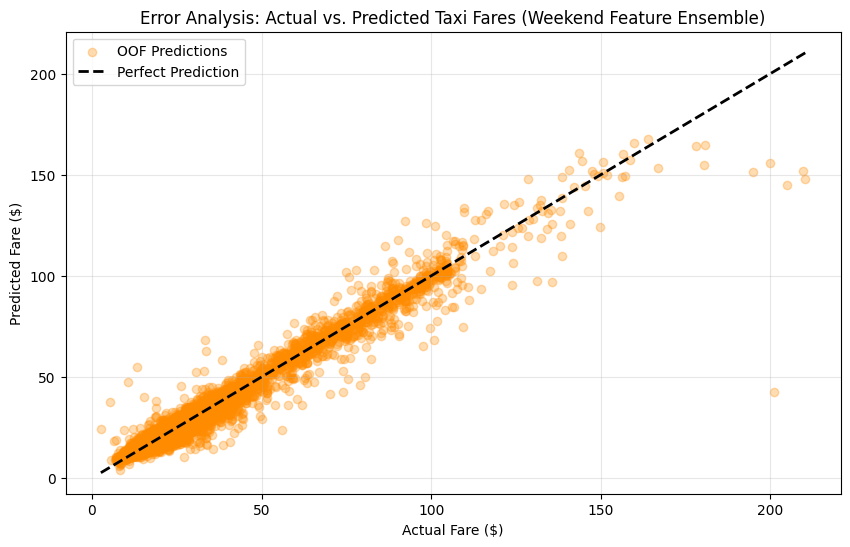

Out-of-Fold Mean Absolute Error (MAE): 2.6807
Model Bias / Mean Residual Error: 0.0236
Out-of-Fold Root Mean Squared Error (RMSE): 4.7318


In [6]:
# Compute residuals based on LightGBM out-of-fold predictions
oof_residuals = y - oof_preds_lgb

# Plot Actual vs Predicted Fares
plt.figure(figsize=(10, 6))
plt.scatter(y, oof_preds_lgb, alpha=0.3, color='darkorange', label='OOF Predictions')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Fare ($)')
plt.ylabel('Predicted Fare ($)')
plt.title('Error Analysis: Actual vs. Predicted Taxi Fares (Weekend Feature Ensemble)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Print Error Statistics
print(f"Out-of-Fold Mean Absolute Error (MAE): {np.abs(oof_residuals).mean():.4f}")
print(f"Model Bias / Mean Residual Error: {oof_residuals.mean():.4f}")
print(f"Out-of-Fold Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y, oof_preds_lgb)):.4f}")